<a href="https://colab.research.google.com/github/Megan-28/earthquake-soil-liquefaction-prediction/blob/main/earthquake_soil_liquifaction_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving liquefaction_dataset_200_rows.csv to liquefaction_dataset_200_rows.csv


In [ ]:
import pandas as pd

data = pd.read_csv("liquefaction_dataset_200_rows.csv")

print(data.head())

   SPT_N   PGA  Magnitude   CSR  Effective_Stress  Total_Stress  \
0      8  0.17        8.4  0.37               152           168   
1     13  0.35        6.3  0.41               126           164   
2     18  0.32        5.9  0.34               159           197   
3      9  0.14        5.6  0.40               193           230   
4     16  0.25        7.4  0.39               139           174   

   Groundwater_Depth  Liquefaction  
0                0.8             1  
1                1.9             1  
2                4.7             1  
3                4.5             1  
4                4.9             1  


In [ ]:
!pip install pyswarms

In [ ]:
!pip install pyswarms tensorflow

In [ ]:
!pip install pandas scikit-learn tensorflow

In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

import pyswarms as ps

# -----------------------------
# Load Dataset
# -----------------------------
data = pd.read_csv("liquefaction_dataset_200_rows.csv")

# Input Features
X = data.drop("Liquefaction", axis=1)

# Output Label
y = data["Liquefaction"]

# -----------------------------
# Train Test Split
# -----------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# -----------------------------
# Feature Scaling
# -----------------------------
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# -----------------------------
# PSO Objective Function
# -----------------------------
def objective_function(params):

    n_particles = params.shape[0]
    losses = []

    for i in range(n_particles):

        # Extract parameters from particle
        neurons = int(params[i][0])
        learning_rate = params[i][1]
        batch_size = int(params[i][2])

        # Prevent invalid values
        neurons = max(4, min(neurons, 20))
        batch_size = max(4, min(batch_size, 16))

        # Build ANN Model
        model = Sequential()

        model.add(Dense(neurons, activation='relu', input_shape=(X_train.shape[1],)))
        model.add(Dense(8, activation='relu'))
        model.add(Dense(1, activation='sigmoid'))

        optimizer = Adam(learning_rate=learning_rate)

        model.compile(
            optimizer=optimizer,
            loss='binary_crossentropy',
            metrics=['accuracy']
        )

        # Train Model
        model.fit(
            X_train,
            y_train,
            epochs=20,
            batch_size=batch_size,
            verbose=0
        )

        # Predict on test set
        y_pred = model.predict(X_test, verbose=0)
        y_pred = (y_pred > 0.5).astype(int)

        # Accuracy
        accuracy = accuracy_score(y_test, y_pred)

        # PSO minimizes, so use negative accuracy
        losses.append(-accuracy)

    return np.array(losses)

# -----------------------------
# PSO Settings
# -----------------------------
options = {
    'c1': 0.5,
    'c2': 0.3,
    'w': 0.9
}

# Bounds for:
# neurons, learning_rate, batch_size
bounds = (
    np.array([4, 0.0001, 4]),
    np.array([20, 0.01, 16])
)

# Create PSO Optimizer
optimizer = ps.single.GlobalBestPSO(
    n_particles=5,
    dimensions=3,
    options=options,
    bounds=bounds
)

# Run PSO
best_cost, best_pos = optimizer.optimize(objective_function, iters=10)

# -----------------------------
# Best Parameters Found
# -----------------------------
best_neurons = int(best_pos[0])
best_learning_rate = best_pos[1]
best_batch_size = int(best_pos[2])

print("Best Hidden Neurons:", best_neurons)
print("Best Learning Rate:", best_learning_rate)
print("Best Batch Size:", best_batch_size)

# -----------------------------
# Train Final ANN Model
# -----------------------------
final_model = Sequential()

final_model.add(Dense(best_neurons, activation='relu', input_shape=(X_train.shape[1],)))
final_model.add(Dense(8, activation='relu'))
final_model.add(Dense(1, activation='sigmoid'))

final_optimizer = Adam(learning_rate=best_learning_rate)

final_model.compile(
    optimizer=final_optimizer,
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history = final_model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=best_batch_size,
    validation_split=0.2
)

# -----------------------------
# Final Predictions
# -----------------------------
y_pred = final_model.predict(X_test)
y_pred = (y_pred > 0.5).astype(int)

# -----------------------------
# Evaluation
# -----------------------------
accuracy = accuracy_score(y_test, y_pred)

print("\nFinal Accuracy:", accuracy)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

2026-04-10 14:44:48,680 - pyswarms.single.global_best - INFO - Optimize for 10 iters with {'c1': 0.5, 'c2': 0.3, 'w': 0.9}
pyswarms.single.global_best:   0%|          |0/10/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Se

Best Hidden Neurons: 18
Best Learning Rate: 0.009904250137649277
Best Batch Size: 9
Epoch 1/50


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.7031 - loss: 0.5919 - val_accuracy: 0.7500 - val_loss: 0.5511
Epoch 2/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8203 - loss: 0.4139 - val_accuracy: 0.7500 - val_loss: 0.4800
Epoch 3/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8516 - loss: 0.3239 - val_accuracy: 0.8125 - val_loss: 0.4535
Epoch 4/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9141 - loss: 0.2669 - val_accuracy: 0.8125 - val_loss: 0.4200
Epoch 5/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9219 - loss: 0.2057 - val_accuracy: 0.8125 - val_loss: 0.3787
Epoch 6/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9453 - loss: 0.1674 - val_accuracy: 0.9062 - val_loss: 0.3485
Epoch 7/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9531 - loss: 0.1355 - val_accuracy: 0.8750 - val_loss: 0.3574
Epoch 8/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9766 - loss: 0.0992 - val_accuracy: 0.9375 - val_loss: 0.3238
Ep

In [ ]:
!pip install pywavelets pyswarms tensorflow scikit-learn pandas matplotlib

2026-04-10 17:25:14,472 - pyswarms.single.global_best - INFO - Optimize for 20 iters with {'c1': 0.5, 'c2': 0.3, 'w': 0.9}
pyswarms.single.global_best:   0%|          |0/20/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Se

Best Hidden Neurons: 21
Best Learning Rate: 0.007085147124069296
Best Batch Size: 20
Epoch 1/50


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - accuracy: 0.7578 - loss: 0.5745 - val_accuracy: 0.7188 - val_loss: 0.4101
Epoch 2/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.7969 - loss: 0.4398 - val_accuracy: 0.7500 - val_loss: 0.3656
Epoch 3/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8203 - loss: 0.3698 - val_accuracy: 0.7500 - val_loss: 0.3527
Epoch 4/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8203 - loss: 0.3769 - val_accuracy: 0.7500 - val_loss: 0.3385
Epoch 5/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.8281 - loss: 0.3268 - val_accuracy: 0.7812 - val_loss: 0.3280
Epoch 6/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8203 - loss: 0.3023 - val_accuracy: 0.7812 - val_loss: 0.3260
Epoch 7/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.8125 - loss: 0.3138 - val_accuracy: 0.7812 - val_loss: 0.3329
Epoch 8/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8203 - loss: 0.2663 - val_accuracy: 0.7812 - val_loss: 0.3097
Epoch 9/50


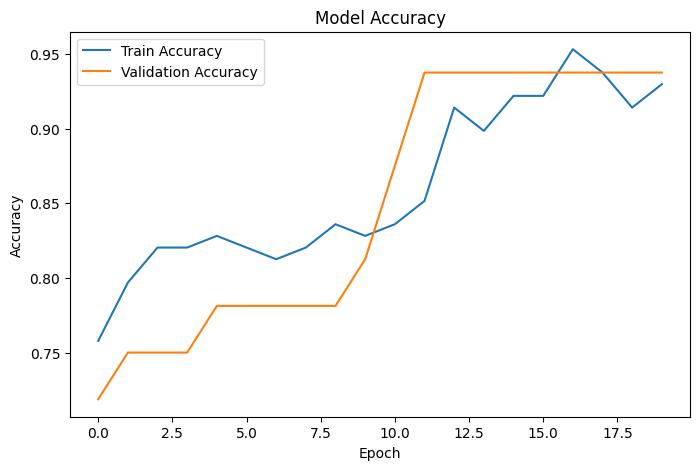

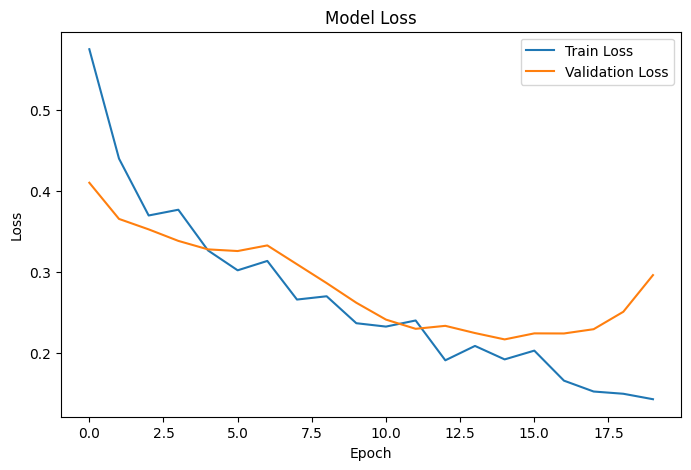

In [ ]:
# Import Libraries
import pandas as pd
import numpy as np
import pywt
import pyswarms as ps
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
# Load Dataset

data = pd.read_csv("liquefaction_dataset_200_rows.csv")


# Separate Input and Output

X = data.drop("Liquefaction", axis=1)
y = data["Liquefaction"]


# Feature Scaling

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Add Wavelet Features

wavelet_features = []

for row in X_scaled:
    coeffs = pywt.wavedec(row, 'db1', level=1)
    features = np.concatenate(coeffs)
    wavelet_features.append(features)

wavelet_features = np.array(wavelet_features)

# Combine original + wavelet features
X_final = np.concatenate([X_scaled, wavelet_features], axis=1)

# Train Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X_final, y, test_size=0.2, random_state=42
)

# PSO Objective Function
# Optimizing:
# 1. Hidden Neurons
# 2. Learning Rate
# 3. Batch Size

def objective_function(params):

    n_particles = params.shape[0]
    losses = []

    for i in range(n_particles):

        neurons = int(params[i][0])
        learning_rate = params[i][1]
        batch_size = int(params[i][2])

        neurons = max(4, min(neurons, 32))
        batch_size = max(4, min(batch_size, 32))

        # Build Model
        model = Sequential()

        model.add(Dense(neurons, activation='relu', input_shape=(X_train.shape[1],)))
        model.add(Dropout(0.3))

        model.add(Dense(8, activation='relu'))
        model.add(Dropout(0.2))

        model.add(Dense(1, activation='sigmoid'))

        optimizer = Adam(learning_rate=learning_rate)

        model.compile(
            optimizer=optimizer,
            loss='binary_crossentropy',
            metrics=['accuracy']
        )

        # Train Model
        model.fit(
            X_train,
            y_train,
            epochs=15,
            batch_size=batch_size,
            validation_split=0.2,
            verbose=0
        )

        # Predict
        y_pred = model.predict(X_test, verbose=0)
        y_pred = (y_pred > 0.5).astype(int)

        accuracy = accuracy_score(y_test, y_pred)

        # PSO minimizes loss
        losses.append(-accuracy)

    return np.array(losses)

# PSO Configuration

options = {
    'c1': 0.5,
    'c2': 0.3,
    'w': 0.9
}

# Bounds:
# hidden neurons, learning rate, batch size
bounds = (
    np.array([4, 0.0001, 4]),
    np.array([32, 0.01, 32])
)

optimizer = ps.single.GlobalBestPSO(
    n_particles=10,
    dimensions=3,
    options=options,
    bounds=bounds
)

# Run PSO

best_cost, best_pos = optimizer.optimize(objective_function, iters=20)


# Best Parameters

best_neurons = int(best_pos[0])
best_learning_rate = best_pos[1]
best_batch_size = int(best_pos[2])

print("Best Hidden Neurons:", best_neurons)
print("Best Learning Rate:", best_learning_rate)
print("Best Batch Size:", best_batch_size)

# Final Model

final_model = Sequential()

final_model.add(Dense(best_neurons, activation='relu', input_shape=(X_train.shape[1],)))
final_model.add(Dropout(0.3))

final_model.add(Dense(8, activation='relu'))
final_model.add(Dropout(0.2))

final_model.add(Dense(1, activation='sigmoid'))

final_optimizer = Adam(learning_rate=best_learning_rate)

final_model.compile(
    optimizer=final_optimizer,
    loss='binary_crossentropy',
    metrics=['accuracy']
)


# Early Stopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)


# Train Final Model

history = final_model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=best_batch_size,
    validation_split=0.2,
    callbacks=[early_stop]
)


# Predictions

y_pred = final_model.predict(X_test)
y_pred = (y_pred > 0.5).astype(int)


# Evaluation

accuracy = accuracy_score(y_test, y_pred)

print("\nFinal Accuracy:", accuracy)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


# Accuracy Graph

plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend()
plt.show()


# Loss Graph

plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend()
plt.show()

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

In [ ]:
# -----------------------------
# Predictions
# -----------------------------
y_pred_prob = final_model.predict(X_test)

y_pred = (y_pred_prob > 0.5).astype(int)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step


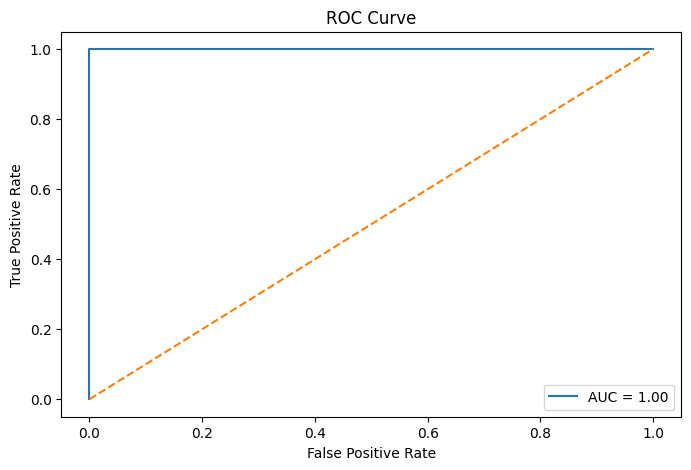

ROC-AUC Score: 1.0


In [ ]:
# -----------------------------
# ROC Curve
# -----------------------------
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)
roc_auc = roc_auc_score(y_test, y_pred_prob)

plt.figure(figsize=(8,5))
plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.2f}')
plt.plot([0, 1], [0, 1], linestyle='--')
plt.title('ROC Curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()

print("ROC-AUC Score:", roc_auc)